**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 9**
Regresión Logística

---

*   NOMBRE: Yan Carlo Jiménez De La Rosa, José Arnulfo Juárez Figueroa, Gael Isaac Jurado Romero, José Pablo Kiesling Lange
*   EQUIPO: 33

En esta actividad trabajarás con el archivo `breast_cancer.csv`, basado en un conjunto de datos sobre características de tumores mamarios, disponible en el repositorio UCI Machine Learning.

Los datos fueron recopilados para analizar si un tumor es maligno (M) o benigno (B) a partir de medidas extraídas de imágenes de biopsias. Las variables incluidas describen propiedades morfológicas y de textura del tumor y se presentan en tres tipos de medida para cada característica:

* `_mean`: valor promedio de la característica en el tumor
* `_se`: error estándar de la característica (variabilidad de la medición)
* `_worst`: peor valor observado de la característica en el tumor

Los indicadores incluidos son:
* `radius_mean` / `radius_se` / `radius_worst`:	Radio del tumor
* `texture_mean` / `texture_se` / `texture_worst`:	Textura del tumor (desviación estándar de intensidad)
* `perimeter_mean` / `perimeter_se` / `perimeter_worst`:	Perímetro del tumor
* `area_mean` / `area_se` / `area_worst`:	Área del tumor
* `smoothness_mean` / `smoothness_se` / `smoothness_worst`:	Suavidad (irregularidad del borde)
* `compactness_mean` / `compactness_se` / `compactness_worst`:	Compacidad (perimeter^2 / area - 1)
* `concavity_mean` / `concavity_se` / `concavity_worst`:	Concavidad de los contornos
* `concave points_mean` / `concave points_se` / `concave points_worst`:	Número de puntos cóncavos en el contorno
* `symmetry_mean` / `symmetry_se` / `symmetry_worst`:	Simetría del tumor
* `fractal_dimension_mean` / `fractal_dimension_se` / `fractal_dimension_worst`:	Dimensión fractal del contorno (complejidad)
* `diagnosis`: Indica si el tumor es benigno (B) o maligno (M). Es la variable de salida o *target*

In [2]:
# Importar las bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score

1. Descarga el archivo: `breast_cancer.csv` y guarda, en un dataframe (`cancer_df`), todos sus registros.
* Haz que la columna `id` sea el nuevo índice.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.
* Obtén las estadísticas descriptivas, separando las variables numéricas (con asimetría y curtosis) y las categóricas.

In [3]:
url = "https://raw.githubusercontent.com/GJ030/Ciencia_datos/main/9.2%20Actividad%209%20-%20Regresi%C3%B3n%20log%C3%ADstica/breast_cancer.csv"
cancer_df = pd.read_csv(url, index_col="id")
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

In [4]:
cancer_df.isna().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [5]:
n_dup = cancer_df.duplicated().sum()
print("Registros duplicados:", n_dup)
if n_dup > 0:
    cancer_df = cancer_df.drop_duplicates().reset_index(drop=True)

Registros duplicados: 0


In [6]:
cancer_df.describe().T.assign(skew=cancer_df.skew(numeric_only=True),
                              kurtosis=cancer_df.kurt(numeric_only=True))

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000,0.942380,0.845522
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000,0.650450,0.758319
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000,0.990650,0.972214
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000,1.645732,3.652303
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340,0.456324,0.855975
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540,1.190123,1.650130
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680,1.401180,1.998638
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120,1.171180,1.066556
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400,0.725609,1.287933
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744,1.304489,3.005892


In [7]:
cancer_df.describe(exclude="number").T

,count,unique,top,freq
diagnosis,569,2,B,357


**Respuesta 1**

Después de usar `id` como índice, el dataframe tiene 31 columnas: 30 numéricas (`float64`) y 1 de texto (`diagnosis`). Ninguna columna tiene valores faltantes y no hay registros duplicados, por lo que no se eliminó nada y se conservan los 569 registros. Todas las variables numéricas tienen asimetría positiva (sesgo a la derecha). Las más sesgadas son las de error estándar, como `area_se` (asimetría 5.45, curtosis 49.2) y `concavity_se` (5.11 y 48.9), lo que indica colas largas y valores atípicos altos; en cambio, `texture_mean` (0.65) y `smoothness_mean` (0.46) son más simétricas. La variable categórica `diagnosis` tiene 2 categorías y la más frecuente es `B` (357 registros).

2. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Calcula y visualiza la distribución porcentual de la variable `diagnosis` usando un gráfico de barras, mostrando el porcentaje encima de cada barra. ¿Por qué la distribución de la salida es relevante en un problema de clasificación?
* Genera un pairplot de las variables físicas del conjunto _mean (`radius_mean`, `perimeter_mean`, `area_mean`, `texture_mean`) coloreando por la variable `diagnosis`. ¿Qué relaciones observas entre las variables físicas? ¿Qué diferencias hay entre los tumores benignos y malignos?
* Crea histogramas apilados de las variables morfológicas (`smoothness_mean`, `compactness_mean`, `concavity_mean`, `concave points_mean`, `symmetry_mean`, `fractal_dimension_mean`) coloreando por `diagnosis` para explorar la distribución de cada variable según el tipo de tumor. ¿Alguna variable parece ser un buen discriminador entre las clases?

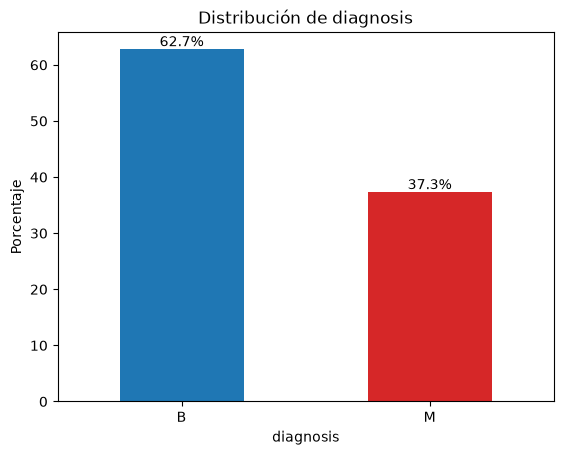

In [8]:
diag_pct = cancer_df["diagnosis"].value_counts(normalize=True) * 100
ax = diag_pct.plot.bar(color=["tab:blue", "tab:red"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_ylabel("Porcentaje")
ax.set_title("Distribución de diagnosis")
plt.show()

**Respuesta 2 (distribución de `diagnosis`)**

El 62.7% de los tumores son benignos y el 37.3% malignos: hay un desbalance moderado. La distribución de la salida es relevante porque la exactitud puede engañar (un modelo que predijera siempre "benigno" tendría 62.7% de exactitud sin detectar ningún tumor maligno), porque el modelo tiende a favorecer la clase mayoritaria y porque obliga a evaluar con métricas por clase como el recall y la precisión.

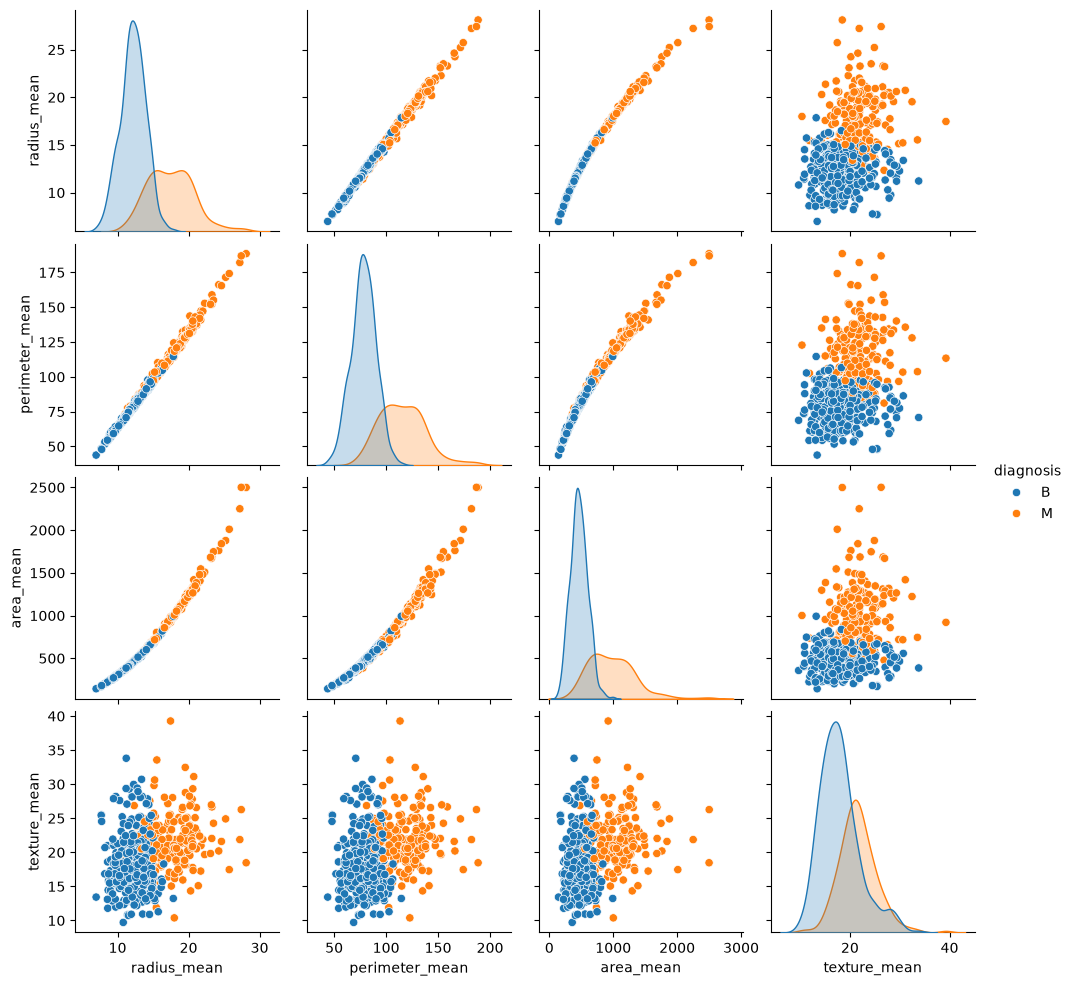

In [9]:
sns.pairplot(cancer_df, vars=["radius_mean", "perimeter_mean", "area_mean", "texture_mean"],
             hue="diagnosis", hue_order=["B", "M"])
plt.show()

**Respuesta 2 (pairplot)**

`radius_mean`, `perimeter_mean` y `area_mean` tienen una relación lineal casi perfecta entre sí (la del área con las otras dos es ligeramente curva), mientras que `texture_mean` casi no se relaciona con ellas. Los tumores malignos (naranja) tienen valores mucho mayores de radio, perímetro y área, y también más dispersión, mientras que los benignos (azul) se concentran en valores pequeños. Con estas tres variables las clases se separan bastante bien, con un traslape pequeño en la zona intermedia; en `texture_mean` los malignos tienen valores algo más altos, pero el traslape es grande.

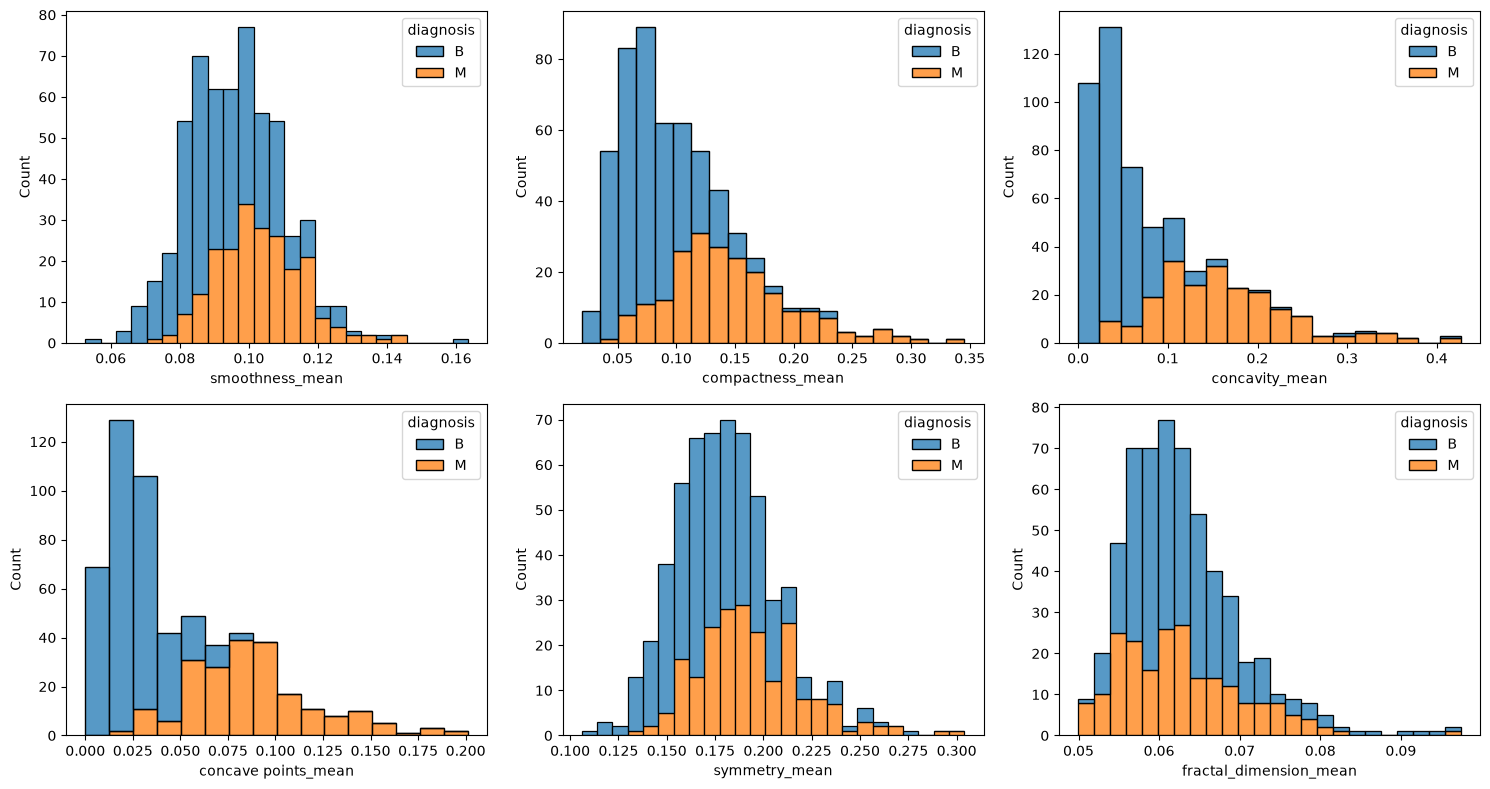

In [10]:
morph_cols = ["smoothness_mean", "compactness_mean", "concavity_mean",
              "concave points_mean", "symmetry_mean", "fractal_dimension_mean"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, morph_cols):
    sns.histplot(data=cancer_df, x=col, hue="diagnosis", hue_order=["B", "M"],
                 multiple="stack", bins="auto", ax=ax)
plt.tight_layout()
plt.show()

**Respuesta 2 (histogramas apilados)**

`concave points_mean` y `concavity_mean` son los mejores discriminadores: los tumores benignos se concentran cerca de cero y los malignos aparecen casi todos en valores más altos. `compactness_mean` separa de forma parcial, también con los malignos en valores más altos. `smoothness_mean`, `symmetry_mean` y `fractal_dimension_mean` tienen un traslape muy grande entre las dos clases, por lo que discriminan poco por sí solas.

3. Antes de realizar el análisis de correlación, crea una copia del dataframe (`cancer_copy`).
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos. La alta correlación entre las variables del conjunto _mean y _worst es inevitable, ya que las columnas _worst representan esencialmente los valores máximos de las mismas características medidas en _mean. Elimina las columnas _worst para simplificar el análisis.
* Imprime nuevamente los pares con correlación superior a 0.9. Como habías observado previamente, existen relaciones lineales entre `radius`, `perimeter` y `area`, por lo que era esperable encontrar altas correlaciones. De estas tres medidas, ¿cuál mantendrías y por qué? Elimina todas las variables de los otros dos conjuntos.
* Dibuja un mapa de calor con la matriz de correlación para identificar si prevalece alguna correlación relevante. Si eliminas alguna otra variable, justifica tu elección.

In [11]:
cancer_copy = cancer_df.copy()

def high_corr_pairs(df, threshold=0.9):
    corr = df.drop(columns="diagnosis").corr()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    return upper[upper.abs() > threshold].sort_values(ascending=False)

print(high_corr_pairs(cancer_copy))

radius_mean          perimeter_mean          0.997855
radius_worst         perimeter_worst         0.993708
radius_mean          area_mean               0.987357
perimeter_mean       area_mean               0.986507
radius_worst         area_worst              0.984015
perimeter_worst      area_worst              0.977578
radius_se            perimeter_se            0.972794
perimeter_mean       perimeter_worst         0.970387
radius_mean          radius_worst            0.969539
perimeter_mean       radius_worst            0.969476
radius_mean          perimeter_worst         0.965137
area_mean            radius_worst            0.962746
                     area_worst              0.959213
                     perimeter_worst         0.959120
radius_se            area_se                 0.951830
perimeter_mean       area_worst              0.941550
radius_mean          area_worst              0.941082
perimeter_se         area_se                 0.937655
concavity_mean       concave

In [12]:
worst_cols = [c for c in cancer_copy.columns if c.endswith("_worst")]
cancer_copy = cancer_copy.drop(columns=worst_cols)
print(high_corr_pairs(cancer_copy))

radius_mean     perimeter_mean         0.997855
                area_mean              0.987357
perimeter_mean  area_mean              0.986507
radius_se       perimeter_se           0.972794
                area_se                0.951830
perimeter_se    area_se                0.937655
concavity_mean  concave points_mean    0.921391
dtype: float64


In [13]:
area_perim_cols = [c for c in cancer_copy.columns if c.startswith(("perimeter", "area"))]
cancer_copy = cancer_copy.drop(columns=area_perim_cols)
print(area_perim_cols)

['perimeter_mean', 'area_mean', 'perimeter_se', 'area_se']


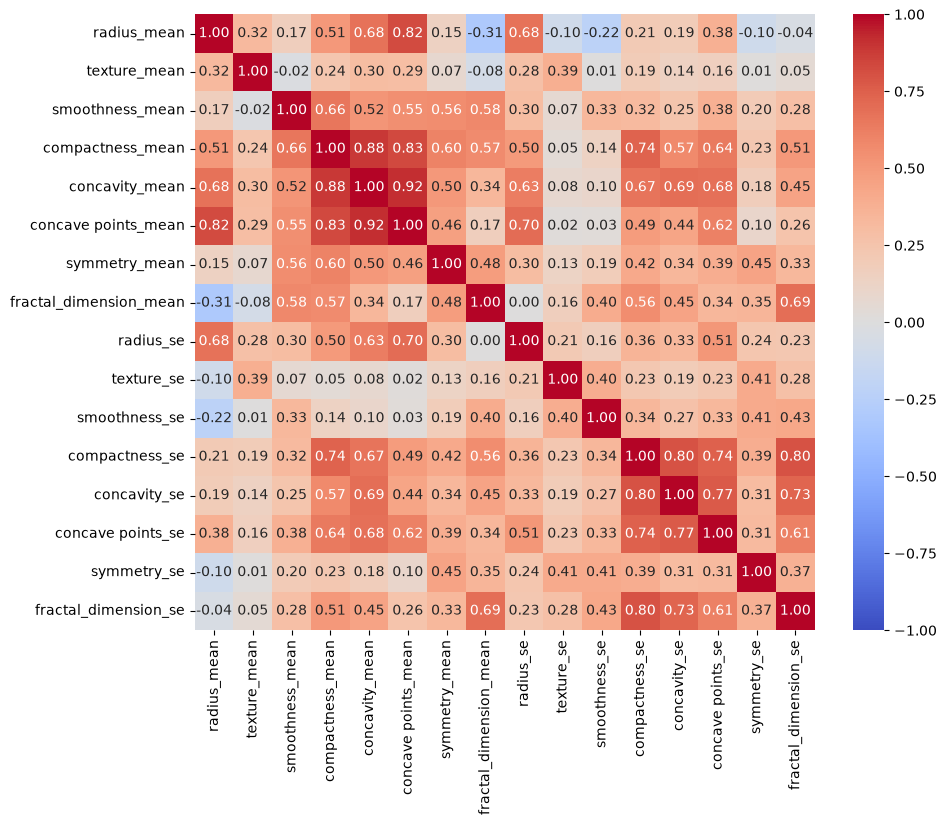

In [14]:
plt.figure(figsize=(10, 8))
sns.heatmap(cancer_copy.drop(columns="diagnosis").corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

**Respuesta 3**

Con un umbral de 0.9 aparecen 21 pares, casi todos entre variables `_mean` y `_worst` de la misma característica y entre `radius`, `perimeter` y `area`; por eso se eliminaron las 10 columnas `_worst`. Aun así quedan 7 pares, de los cuales 6 son de `radius`, `perimeter` y `area` (por ejemplo `radius_mean` y `perimeter_mean`, 0.998). De estas tres medidas mantendría `radius`, porque es la medida geométrica más directa y simple (una longitud), mientras que el perímetro y el área son medidas derivadas del mismo tamaño del tumor y aportan casi la misma información. Se eliminaron `perimeter_mean`, `area_mean`, `perimeter_se` y `area_se`.

En el mapa de calor solo queda un par por encima de 0.9: `concavity_mean` con `concave points_mean` (0.92). No eliminé ninguna otra variable: la correlación apenas supera el umbral, ambas fueron las mejores discriminadoras en la pregunta 2 y las demás correlaciones altas son moderadas (por ejemplo 0.88 entre `compactness_mean` y `concavity_mean`), por lo que no representan una redundancia casi total como la de `radius`, `perimeter` y `area`.

4. Separa las variables predictoras `X` de la variable de salida `y`, usando el dataframe original `cancer_df` (la eliminación de variables correlacionadas se integrará en el pipeline).
* Codifica `diagnosis` como 0 (Benigno) y 1 (Maligno).
* Divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Para evaluar los modelos que se construirán, define una función llamada `evaluate_model` que reciba los valores reales y las predicciones e imprima las métricas de recall, precisión y exactitud (accuracy).

In [15]:
X = cancer_df.drop(columns="diagnosis")
y = cancer_df["diagnosis"].map({"B": 0, "M": 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

def evaluate_model(y_true, y_pred):
    recall = recall_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    accuracy = accuracy_score(y_true, y_pred)
    print(f"Recall: {recall:.4f}")
    print(f"Precisión: {precision:.4f}")
    print(f"Exactitud (accuracy): {accuracy:.4f}")
    return recall, precision, accuracy

5. Prepara un transformador denominado `preprocessing`, usando ColumnTransformer, para borrar las columnas altamente correlacionadas (identificadas en el ejercicio 3) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.
* Crea un pipeline que integre el transformador y regresión logística para  entrenar un modelo.
* Evalúa el desempeño del modelo en el conjunto de prueba empleando la función `evaluate_model`.
* Integra los resultados en un dataframe que contenga el nombre del modelo (*Correlation_Clean*) y una columna para cada métrica calculada.

In [16]:
drop_cols = worst_cols + area_perim_cols
preprocessing = ColumnTransformer([("drop_corr", "drop", drop_cols)],
                                  remainder="passthrough", verbose_feature_names_out=False)

# max_iter=1000 para que el optimizador converja
correlation_clean = make_pipeline(preprocessing, LogisticRegression(max_iter=1000))
correlation_clean.fit(X_train, y_train)

recall, precision, accuracy = evaluate_model(y_test, correlation_clean.predict(X_test))
results = pd.DataFrame({"Model": ["Correlation_Clean"], "Recall": [recall],
                        "Precision": [precision], "Accuracy": [accuracy]})
results

Recall: 0.7619
Precisión: 0.8889
Exactitud (accuracy): 0.8772


,Model,Recall,Precision,Accuracy
0,Correlation_Clean,0.761905,0.888889,0.877193


6. Una alternativa para reducir la multicolinealidad es el análisis de componentes principales. Construye un pipeline que incluya escalado estándar, PCA y regresión logística, manteniendo el número mínimo de componentes principales que expliquen al menos el 90% de la varianza.
* Entrena el modelo utilizando el conjunto de entrenamiento y evalúalo en el conjunto de prueba.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Standard_PCA*.
* ¿Cuántos componentes principales se emplearon?

In [17]:
standard_pca = make_pipeline(StandardScaler(), PCA(n_components=0.90), LogisticRegression(max_iter=1000))
standard_pca.fit(X_train, y_train)

recall, precision, accuracy = evaluate_model(y_test, standard_pca.predict(X_test))
results.loc[len(results)] = ["Standard_PCA", recall, precision, accuracy]
print("Componentes principales:", standard_pca[1].n_components_)

Recall: 0.9286
Precisión: 1.0000
Exactitud (accuracy): 0.9737
Componentes principales: 7


**Respuesta 6**

Se emplearon 7 componentes principales, el mínimo que explica al menos el 90% de la varianza de las 30 variables escaladas.

7. Como intento de mejorar las métricas del modelo, y dado que todas las variables presentan sesgo, aplica una normalización utilizando Yeo-Johnson. Para ello:
* Crea un pipeline que integre el transformador `preprocessing`, una transformación Yeo-Johnson y regresión logística.
* Entrena el modelo utilizando el conjunto de entrenamiento y evalúalo en el conjunto de prueba.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Correlation_Yeo*.

In [18]:
correlation_yeo = make_pipeline(preprocessing, PowerTransformer(method="yeo-johnson"),
                                LogisticRegression(max_iter=1000))
correlation_yeo.fit(X_train, y_train)

recall, precision, accuracy = evaluate_model(y_test, correlation_yeo.predict(X_test))
results.loc[len(results)] = ["Correlation_Yeo", recall, precision, accuracy]

Recall: 0.9524
Precisión: 1.0000
Exactitud (accuracy): 0.9825


8. Del modelo anterior, obtén los nombres de los predictores empleados. ¿Cuántos son?
* Revisa los coeficientes del modelo de regresión logística y analiza su magnitud para identificar las variables 10 más influyentes.
* Grafícalas en un barplot horizontal, mostrando el valor del coeficiente y respetando su signo.

16 predictores:
['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se']


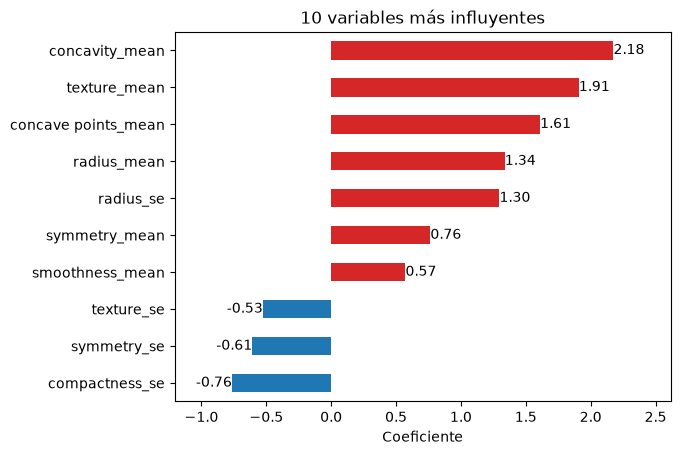

In [19]:
feature_names = correlation_yeo[:-1].get_feature_names_out()
print(len(feature_names), "predictores:")
print(list(feature_names))

coefs = pd.Series(correlation_yeo[-1].coef_[0], index=feature_names)
top10 = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)

ax = top10.sort_values().plot.barh(color=np.where(top10.sort_values() > 0, "tab:red", "tab:blue"))
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.margins(x=0.15)
ax.set_xlabel("Coeficiente")
ax.set_title("10 variables más influyentes")
plt.show()

**Respuesta 8**

El modelo usa 16 predictores: las columnas que quedan después de eliminar las 10 `_worst` y las 4 de perímetro y área. Como la transformación Yeo-Johnson deja las variables estandarizadas, la magnitud de los coeficientes es comparable entre variables. Las más influyentes son `concavity_mean` (2.18), `texture_mean` (1.91), `concave points_mean` (1.61), `radius_mean` (1.34) y `radius_se` (1.30), todas con signo positivo: al aumentar, crece la probabilidad de que el tumor sea maligno. Tres de las diez tienen signo negativo (`compactness_se`, `symmetry_se` y `texture_se`), es decir, a igualdad de las demás variables, valores altos de ellas reducen esa probabilidad. Como `concavity_mean` y `concave points_mean` están correlacionadas (0.92), su efecto individual debe interpretarse con cuidado.

9. Imprime el dataframe de resultados.
* Dibuja la matriz de confusión del mejor modelo. ¿Qué significa cada valor en ella?
* Dibuja la curva ROC del mismo modelo y describe lo que indica sobre su capacidad para distinguir entre clases.

In [20]:
print(results)

               Model    Recall  Precision  Accuracy
0  Correlation_Clean  0.761905   0.888889  0.877193
1       Standard_PCA  0.928571   1.000000  0.973684
2    Correlation_Yeo  0.952381   1.000000  0.982456


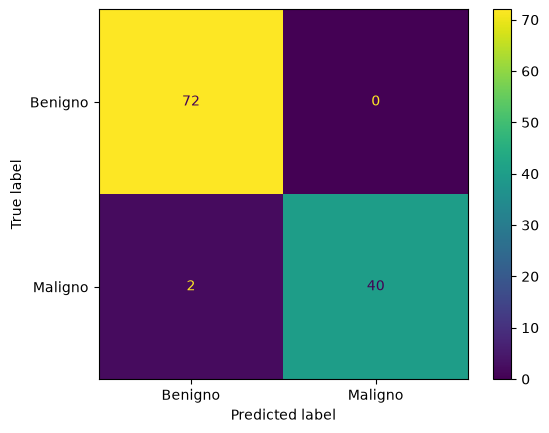

In [21]:
best_model = correlation_yeo
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["Benigno", "Maligno"])
plt.show()

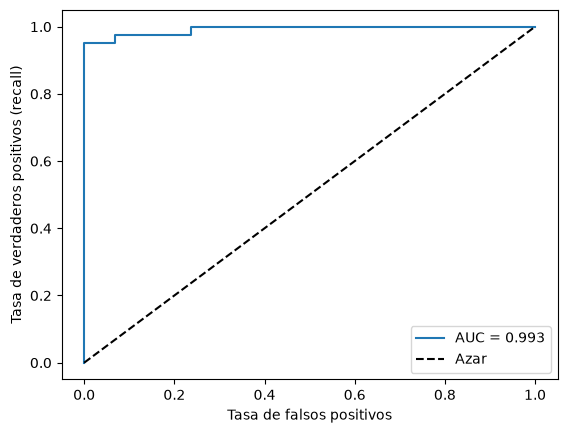

In [22]:
y_proba = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_proba):.3f}")
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.legend()
plt.show()

**Respuesta 9**

El mejor modelo es `Correlation_Yeo`: obtiene el mayor recall (0.952) y la mayor exactitud (0.982), con precisión de 1.0, igual que `Standard_PCA`; `Correlation_Clean` tuvo el peor desempeño en las tres métricas (recall 0.762, precisión 0.889 y exactitud 0.877). La normalización Yeo-Johnson mejoró el modelo con la misma selección de variables.

Matriz de confusión (filas: clase real; columnas: clase predicha) sobre los 114 registros de prueba:
* **72 (verdaderos negativos):** tumores benignos que el modelo clasificó como benignos.
* **0 (falsos positivos):** tumores benignos clasificados como malignos.
* **2 (falsos negativos):** tumores malignos que el modelo clasificó como benignos, el error más grave en este problema.
* **40 (verdaderos positivos):** tumores malignos clasificados correctamente como malignos.

La curva ROC pasa muy cerca de la esquina superior izquierda y tiene un AUC de 0.993: para casi cualquier umbral el modelo logra una tasa alta de verdaderos positivos con una tasa muy baja de falsos positivos, es decir, distingue muy bien entre tumores benignos y malignos (un AUC de 0.5 sería equivalente al azar, la diagonal punteada).

10. Grafica la distribución de las probabilidades predichas de la clase positiva (Maligno, 1) usando histogramas superpuestos, diferenciando con colores las clases reales Benigno (B) y Maligno (M).
* ¿Cuál es el umbral (*threshold*) por defecto que utiliza scikit-learn para convertir probabilidades en predicciones binarias?
* En un modelo de diagnóstico médico, ¿cuál consideras que es la métrica más importante?
* ¿Cómo cambiarías (disminuir / aumentar) el *threshold*? ¿Por qué?

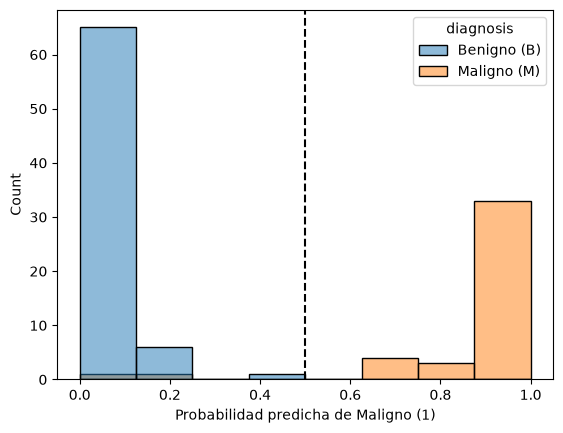

In [23]:
sns.histplot(x=y_proba, hue=y_test.map({0: "Benigno (B)", 1: "Maligno (M)"}), bins="auto")
plt.axvline(0.5, color="k", linestyle="--")
plt.xlabel("Probabilidad predicha de Maligno (1)")
plt.show()

**Respuesta 10**

* **Umbral por defecto:** scikit-learn clasifica como clase positiva (maligno) cuando la probabilidad predicha es mayor o igual a 0.5 (línea punteada en el histograma). Las probabilidades de los benignos se concentran cerca de 0 y las de los malignos cerca de 1, con poco traslape alrededor del umbral.
* **Métrica más importante:** el recall (sensibilidad), porque un falso negativo significa que un tumor maligno no se detecta y el paciente no recibe tratamiento a tiempo, mientras que un falso positivo se resuelve con estudios adicionales. La precisión también importa para no generar biopsias y ansiedad innecesarias, pero es secundaria.
* **Cambio del umbral:** lo disminuiría (por ejemplo a 0.3) para priorizar la sensibilidad: se clasificarían como malignos más tumores, aumentaría el recall y se reducirían los falsos negativos, a cambio de más falsos positivos (menor precisión y especificidad). Lo aumentaría solo si los falsos positivos fueran más costosos que los falsos negativos, porque subiría la precisión y la especificidad a costa de perder casos malignos.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *Claude Code (basado en Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código, depuración y redacción de los análisis. https://claude.com/claude-code

---